# 🚀 CS/SE 4AL3: Tutorial 1
## Data Exploration, Distance Intuition, and OLS

Welcome! Today we cover **Basic Classification & Regression**. We will:

1. Load **Fisher's Iris data** and check feature correlation.
2. See **why we might still use correlated features**.
3. Build **distance-based intuition** with interactive k-NN.
4. See **why feature scaling matters**.
5. Use a **confusion matrix** and precision/recall/F1.
6. Implement **Ordinary Least Squares (OLS)** with matrix math.

## Imports

In [7]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, precision_score,
                             recall_score, f1_score)
import ipywidgets as widgets
from IPython.display import display
from collections import Counter

# Style
sns.set_theme(style="whitegrid", palette="pastel")
plt.rcParams['figure.figsize'] = (8, 6)
np.random.seed(42)

ModuleNotFoundError: No module named 'seaborn'

# 1. Data Exploration & Correlation 🔍

Before modeling, we must understand our data. Iris has 4 features — are any of them **redundant**?

We compute the **Pearson correlation** between features. The `r` value ranges from -1 to +1.

## Load and View Data

In [ ]:
# Load dataset
iris = load_iris(as_frame=True)
df = iris.frame
df["species"] = pd.Categorical.from_codes(iris.target, iris.target_names)

print("Shape:", df.shape)
print("\nClass balance:\n", df["species"].value_counts())
display(df.head())

Shape: (150, 6)

Class balance:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## Heatmap

In [ ]:
# Compute correlation matrix (exclude the target column)
corr_matrix = df[iris.feature_names].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f",
            linewidths=1, vmin=-1, vmax=1, square=True)
plt.title("Feature Correlation Heatmap (Iris Dataset)")
plt.show()

NameError: name 'df' is not defined

1 is the maximum correlation

## 1.1 Do we need highly correlated features?
No

Have to investigate more if it's very high correlation model



### 1.1 Wait, if features are correlated, aren't they redundant?

Looking at the heatmap, **Petal Length** and **Petal Width** are highly correlated ($r = 0.96$). Do we really need both to classify the flowers, or can we get a good separation with just one?


### 1D vs 2D Visualization

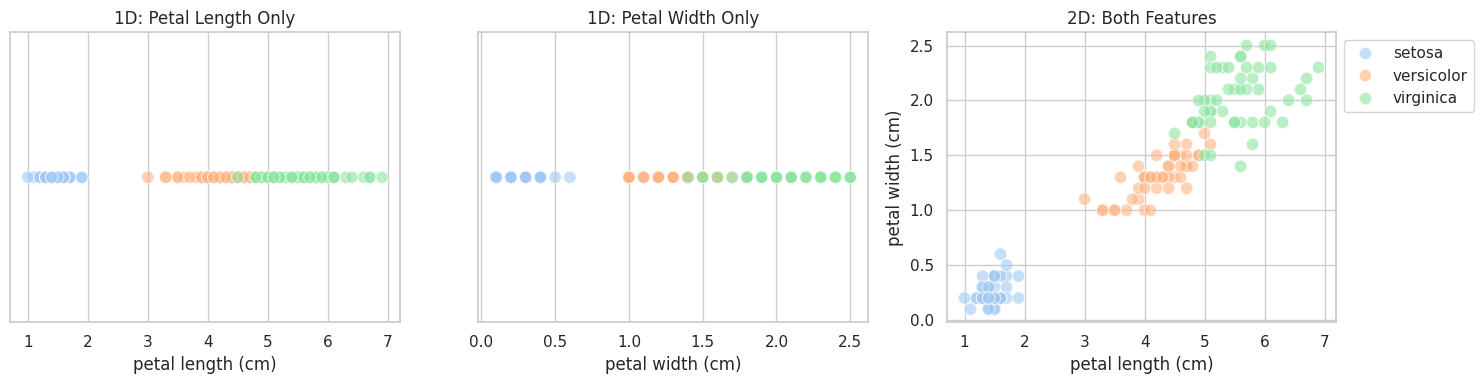

In [ ]:
# 1D vs 2D Feature Separation Demo
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Just Petal Length (1D)
sns.scatterplot(x=df['petal length (cm)'], y=np.zeros(len(df)), hue=df['species'],
                ax=axes[0], s=80, alpha=0.6, legend=False)
axes[0].set_title('1D: Petal Length Only')
axes[0].set_yticks([])

# 2. Just Petal Width (1D)
sns.scatterplot(x=df['petal width (cm)'], y=np.zeros(len(df)), hue=df['species'],
                ax=axes[1], s=80, alpha=0.6, legend=False)
axes[1].set_title('1D: Petal Width Only')
axes[1].set_yticks([])

# 3. Both Features (2D)
sns.scatterplot(x=df['petal length (cm)'], y=df['petal width (cm)'], hue=df['species'],
                ax=axes[2], s=80, alpha=0.6)
axes[2].set_title('2D: Both Features')
axes[2].legend(loc='upper left', bbox_to_anchor=(1, 1))

plt.tight_layout()
plt.show()

# 🗣️ Note: Notice how the green and blue dots (versicolor and virginica)
# overlap a bit on the 1D lines. When we combine them into a 2D space,
# they spread out diagonally, making the boundary much clearer!

# 2. Interactive Nearest Neighbors 📏

**1-NN idea:** To classify a new point, find the closest training point and copy its label.
**k-NN:** Take a vote among the *k* closest points.

**k is a hyperparameter** — you set it, the model doesn't learn it. Run the cell below and drag the slider to see how changing $k$ changes the prediction.


### The Math Behind the Drop: Euclidean Distance

In $k$-NN, we measure the distance between two points $p$ and $q$ (with $n$ features) using the **Euclidean Distance** formula:

$$d(p, q) = \sqrt{\sum_{i=1}^{n} (p_i - q_i)^2}$$


In [ ]:
# Interactive k-NN slider
# Extract two features for 2D plotting
X_vis = df[['petal length (cm)', 'petal width (cm)']].values
y_vis = df['target'].values
target_names = iris.target_names
new_point = np.array([2.5, 0.75])   # The "unknown flower"

def interactive_knn(k):
    plt.figure(figsize=(9, 6))
    plt.scatter(X_vis[:, 0], X_vis[:, 1], c=y_vis, cmap='viridis',
                alpha=0.7, edgecolors='k', s=60)
    plt.scatter(new_point[0], new_point[1], color='red', marker='*',
                s=500, label='Unknown Flower', zorder=5)

    distances = np.sqrt(np.sum((X_vis - new_point)**2, axis=1))
    nearest_indices = np.argsort(distances)[:k]

    neighbor_classes = []
    for idx in nearest_indices:
        neighbor_classes.append(y_vis[idx])
        plt.plot([new_point[0], X_vis[idx][0]],
                 [new_point[1], X_vis[idx][1]],
                 color='black', linestyle='--', linewidth=1.5, alpha=0.6)

    most_common_class_idx = Counter(neighbor_classes).most_common(1)[0][0]
    predicted_species = target_names[most_common_class_idx]

    plt.xlabel('Petal Length (cm)')
    plt.ylabel('Petal Width (cm)')
    plt.title(f'Prediction with k={k}: {predicted_species.upper()}',
              fontsize=14, fontweight='bold')
    plt.legend()
    plt.show()

widgets.interact(interactive_knn,
                 k=widgets.IntSlider(value=1, min=1, max=15, step=2,
                                     description='k Neighbors:'))

interactive(children=(IntSlider(value=1, description='k Neighbors:', max=15, min=1, step=2), Output()), _dom_c…

<function __main__.interactive_knn(k)>

# 3. Why Scaling Matters ⚖️

Scaling or normalizing
Map features to 0 nd 1

coz the data can be like 1 nm to 10 nm

if the value is smaller, it shouldn't be given less value


Distance is dominated by whichever feature has the **largest range**. Features should be treated as *equally important* when measuring distance. Standardization (like z-score scaling) ensures this happens.

❓ **YOUR TURN:** If feature 1 ranges 0–1000 and feature 2 ranges 0–1, which one controls the distance?

### Scaling Demo

In [6]:
# Scaling demo
# Fake dataset: feature 1 has a huge range, feature 2 has a tiny range
X_demo = np.array([[10., 0.1], [12., 0.2],     # class A
                   [90., 0.9], [88., 0.8]])    # class B
y_demo = np.array(["A", "A", "B", "B"])
mystery = np.array([50., 0.15])

print("=== UNSCALED ===")
print("Dist to A[0]:", round(np.linalg.norm(mystery - X_demo[0]), 2))
print("Dist to B[0]:", round(np.linalg.norm(mystery - X_demo[2]), 2))

sc = StandardScaler().fit(X_demo)
Xs = sc.transform(X_demo)
ms = sc.transform([mystery])

print("\n=== SCALED ===")
print("Dist to A[0]:", round(np.linalg.norm(ms - Xs[0]), 2))
print("Dist to B[0]:", round(np.linalg.norm(ms - Xs[2]), 2))

# 🗣️ Takeaway: Always standardize features before using distance-based models like k-NN.

NameError: name 'np' is not defined

# 4. Confusion Matrix & Metrics 📊

Accuracy alone can lie. **The confusion matrix shows *which* mistakes** the model makes.

- **Rows** = actual class
- **Columns** = predicted class
- **Diagonal** = correct ✅  **Off-diagonal** = mistakes ❌

Then we compute:
- **Accuracy** = (TP+TN)/N
- **Precision** = TP/(TP+FP) — "of what I predicted positive, was I right?"
- **Recall** = TP/(TP+FN) — "of actual positives, how many did I catch?"
- **F1** = harmonic mean of the two

### Train & Test

In [35]:
# Train/test split + k-NN fit
# Use all 4 features
X_full = df[iris.feature_names].values
y_full = df["species"].values

# Split, scale, fit
X_tr, X_te, y_tr, y_te = train_test_split(
    X_full, y_full, test_size=0.3, random_state=42, stratify=y_full)

scaler = StandardScaler().fit(X_tr)
X_tr_s = scaler.transform(X_tr)
X_te_s  = scaler.transform(X_te)

knn = KNeighborsClassifier(n_neighbors=5).fit(X_tr_s, y_tr)
y_pred = knn.predict(X_te_s)

print("Test accuracy:", round((y_pred == y_te).mean(), 3))

Test accuracy: 0.911


### Confusion Matrix Output  -- *Very Important for Exams*

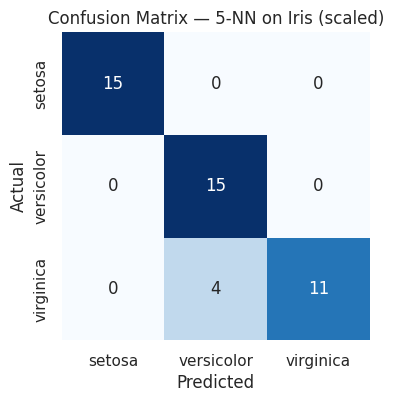

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.79      1.00      0.88        15
   virginica       1.00      0.73      0.85        15

    accuracy                           0.91        45
   macro avg       0.93      0.91      0.91        45
weighted avg       0.93      0.91      0.91        45



In [36]:
# Confusion matrix heatmap
cm = confusion_matrix(y_te, y_pred, labels=list(iris.target_names))

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=iris.target_names,
            yticklabels=iris.target_names,
            cbar=False, square=True)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix — 5-NN on Iris (scaled)")
plt.show()

print(classification_report(y_te, y_pred, zero_division=0))

### Simple Baseline Comparison

In [37]:
# Why accuracy lies
# Simple baseline classifier: always predicts 'setosa'
simple_preds = np.full_like(y_te, "setosa")
print("Simple baseline accuracy:", round((simple_preds == y_te).mean(), 3))

# Full metrics for the real model
print("\nReal 5-NN model:")
print("  Accuracy :", round(accuracy_score(y_te, y_pred), 3))
print("  Precision:", round(precision_score(y_te, y_pred, average='macro'), 3))
print("  Recall   :", round(recall_score(y_te, y_pred, average='macro'), 3))
print("  F1       :", round(f1_score(y_te, y_pred, average='macro'), 3))

Simple baseline accuracy: 0.333

Real 5-NN model:
  Accuracy : 0.911
  Precision: 0.93
  Recall   : 0.911
  F1       : 0.91


# 5. Ordinary Least Squares (OLS) 📈

Goal: Find the relationship between **happiness (h)** and **wealth (r)**.

Hypothesis: $h = \beta_0 + \beta_1 * r$

OLS closed form: $\beta = (X^T X)^{-1} X^T y$

- **β₀, β₁ are parameters** — learned from data
- **Features x are weighted by β's**
- **We minimize the sum of squared residuals d_i²**

### 5.1 The Math Behind OLS: Step-by-Step Derivation

To find the line of best fit, our goal is to find the parameters ($\beta$) that minimize the squared error between our predictions and the actual data[cite: 1].

**1. The Matrix Equation**
Instead of writing an equation for every single data point, we pack everything into matrices[cite: 1]:
$$y = X\beta + e$$
*   $y$: Actual targets (column vector)
*   $X$: Input features (matrix)
*   $\beta$: The weights/slope we want to learn
*   $e$: The error or residuals ($y - \text{predictions}$)[cite: 1]

By rearranging, we define the error as[cite: 1]:
$$e = y - X\beta$$

**2. Squaring the Error**
We want to minimize the *Sum of Squared Errors* (SSE). In matrix math, to square a vector and sum the results, you multiply it by its own transpose ($e^Te$)[cite: 1].
$$e^Te = (y - X\beta)^T(y - X\beta)$$

**3. The Matrix "FOIL" Expansion**
To expand this, we first apply the transpose to the first bracket. A key rule of matrix algebra is that $(X\beta)^T = \beta^TX^T$. So, our equation becomes:
$$e^Te = (y^T - \beta^TX^T)(y - X\beta)$$

Now, we FOIL (First, Outer, Inner, Last) just like regular algebra:
*   **First:** $y^Ty$
*   **Outer:** $-y^TX\beta$
*   **Inner:** $-\beta^TX^Ty$
*   **Last:** $+\beta^TX^TX\beta$

**The Scalar Trick:** In matrix math, the Outer and Inner terms actually compute the exact same single number (a scalar). Because they are identical, we can combine them into $-2\beta^TX^Ty$.

This gives us our fully expanded error equation:
$$e^Te = y^Ty - 2\beta^TX^Ty + \beta^TX^TX\beta$$

**4. Finding the Minimum (Calculus)**
To find the lowest point of the error curve, we take the derivative with respect to $\beta$ and set it to zero. We apply the matrix version of the standard calculus "power rule":
*   $y^Ty$ has no $\beta$, so its derivative is **$0$**.
*   $-2\beta^TX^Ty$ drops the $\beta^T$, leaving **$-2X^Ty$**.
*   $\beta^TX^TX\beta$ acts like $x^2$, so the 2 comes down, leaving **$2X^TX\beta$**.

Set it to zero:
$$-2X^Ty + 2X^TX\beta = 0$$

**5. The Closed-Form Solution**
Now, we just use basic algebra to isolate $\beta$.
$$2X^TX\beta = 2X^Ty$$
$$X^TX\beta = X^Ty$$

To get $\beta$ alone, we must "divide" by $X^TX$. In matrix math, division is done by multiplying by the inverse.
$$\beta = (X^TX)^{-1}X^Ty$$

This final equation is exactly what we compute in Python to find the perfect line!

### Prepare OLS Data

In [40]:
countries = ['Ireland', 'Norway', 'USA', 'Singapore', 'Denmark', 'Switzerland',
             'Finland', 'Netherlands', 'Canada', 'New Zealand', 'Germany',
             'Israel', 'Australia', 'Sweden', 'UK', 'Brazil', 'Mexico', 'India']

wealth_r = np.array([84340, 64341, 61356, 98337, 60000, 75000,
                     49000, 55000, 52000, 45000, 50000, 45000,
                     55000, 54000, 47000, 15000, 18000, 7000], dtype=float)
happiness_h = np.array([7.02, 7.55, 6.89, 6.26, 7.60, 7.50,
                        7.80, 7.40, 7.20, 7.30, 7.00, 7.20,
                        7.20, 7.30, 7.10, 6.30, 6.50, 4.00], dtype=float)

###OLS Math & Plot

Learned Intercept (β₀): 5.9855
Learned Slope     (β₁): 0.00001858


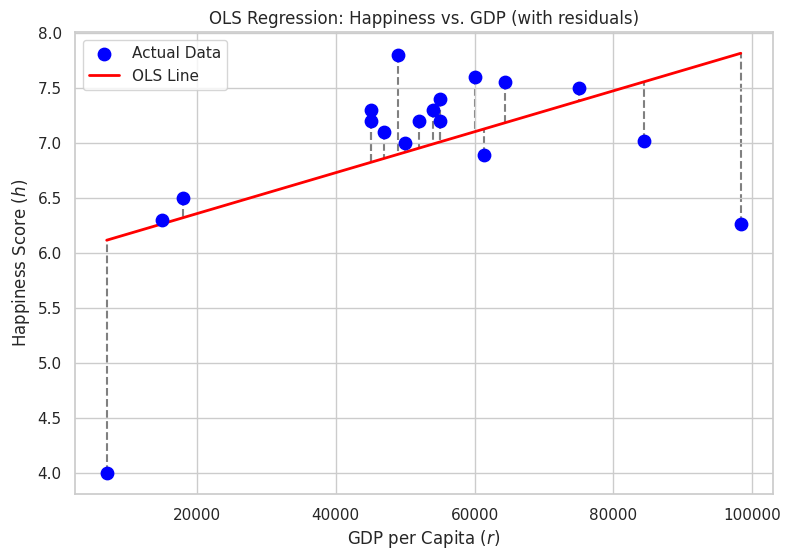

In [43]:
# OLS fit + plot
# Design matrix: [1, x]
X = np.column_stack((np.ones(len(wealth_r)), wealth_r))
Y = happiness_h.reshape(-1, 1)

# Closed-form solution
beta = np.linalg.inv(X.T.dot(X)).dot(X.T).dot(Y)
beta_0, beta_1 = beta[0][0], beta[1][0]

print(f"Learned Intercept (β₀): {beta_0:.4f}")
print(f"Learned Slope     (β₁): {beta_1:.8f}")

# Predictions and residuals
y_pred = X.dot(beta).flatten()

# Plot
plt.figure(figsize=(9, 6))
plt.scatter(wealth_r, happiness_h, color='blue', s=80,
            label='Actual Data', zorder=5)

x_line = np.linspace(wealth_r.min(), wealth_r.max(), 100)
plt.plot(x_line, beta_0 + beta_1 * x_line, color='red',
         linewidth=2, label='OLS Line')

# Residuals (d_i)
for i in range(len(wealth_r)):
    plt.plot([wealth_r[i], wealth_r[i]], [happiness_h[i], y_pred[i]],
             color='gray', linestyle='--', zorder=0)

plt.xlabel('GDP per Capita ($r$)')
plt.ylabel('Happiness Score ($h$)')
plt.title('OLS Regression: Happiness vs. GDP (with residuals)')
plt.legend()
plt.show()

### MSE Check

In [44]:
# Mean Squared Error (MSE)
def mse(y, yhat):
    return float(np.mean((y - yhat) ** 2))

print("MSE on training data:", round(mse(happiness_h, y_pred), 4))
print("RMSE:", round(np.sqrt(mse(happiness_h, y_pred)), 4))

MSE on training data: 0.5147
RMSE: 0.7174
